Error: 0 Reliability: 0.0 %
Error: 0.05 Reliability: 0.0 %
Error: 0.1 Reliability: 0.3 %
Error: 0.2 Reliability: 1.2 %
Error: 0.3 Reliability: 2.4 %


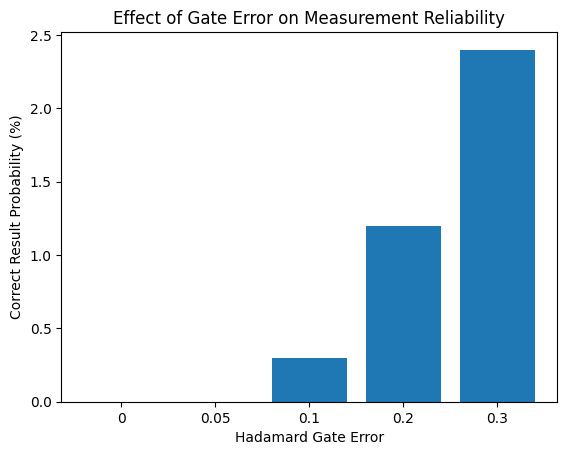

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt


def run_circuit(error):

    qc = QuantumCircuit(2, 1)

    qc.x(1)
    qc.h(0)
    qc.h(1)

    qc.cx(0, 1)

    qc.ry(np.pi / 2 + error, 0)

    qc.measure(0, 0)

    simulator = AerSimulator()
    compiled = transpile(qc, simulator)

    result = simulator.run(
        compiled,
        shots=1000
    ).result()

    counts = result.get_counts()

    return counts.get("1", 0) / 1000

errors = [0, 0.05, 0.10, 0.20, 0.30]

reliability = []

for error in errors:
    reliability.append(run_circuit(error))

for error, value in zip(errors, reliability):
    print(
        "Error:", error,
        "Reliability:", round(value * 100, 2), "%"
    )

plt.bar(
    [str(e) for e in errors],
    [r * 100 for r in reliability]
)

plt.xlabel("Hadamard Gate Error")
plt.ylabel("Correct Result Probability (%)")
plt.title("Effect of Gate Error on Measurement Reliability")
plt.show()